In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("/content/insurance.csv")

In [ ]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


**EDA**

In [ ]:
df.shape

(1338, 7)

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

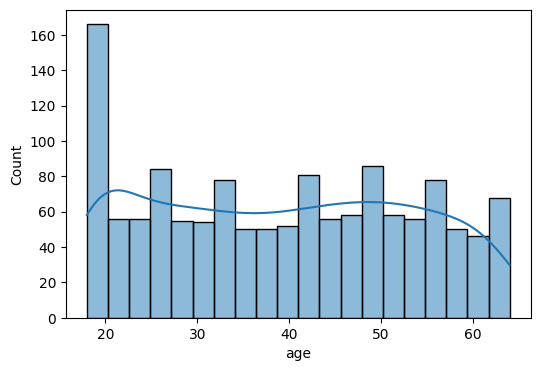

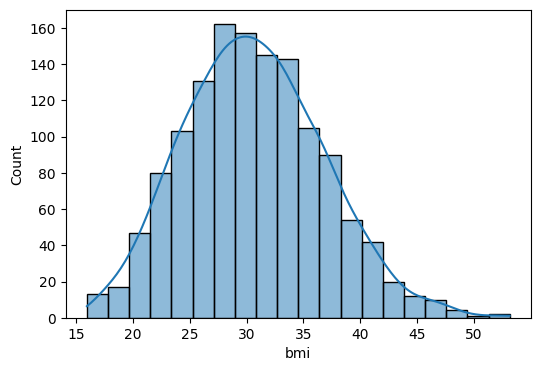

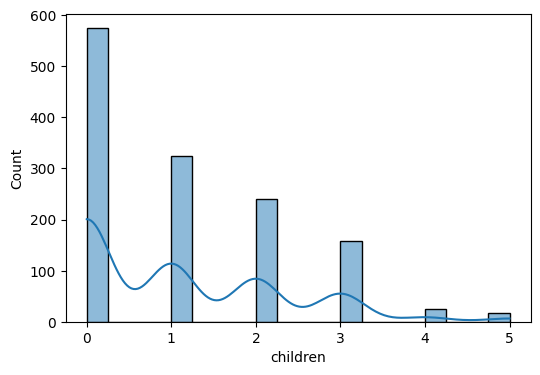

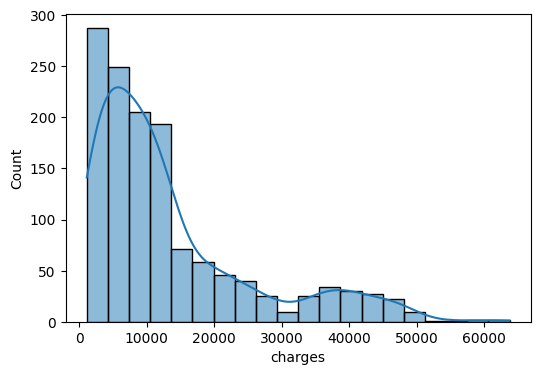

In [ ]:
numeric_columns = ["age",	"bmi","children","charges"]
for col in numeric_columns:
  plt.figure(figsize=(6,4))
  sns.histplot(df[col] ,kde=True, bins=20)

<Axes: xlabel='children', ylabel='count'>

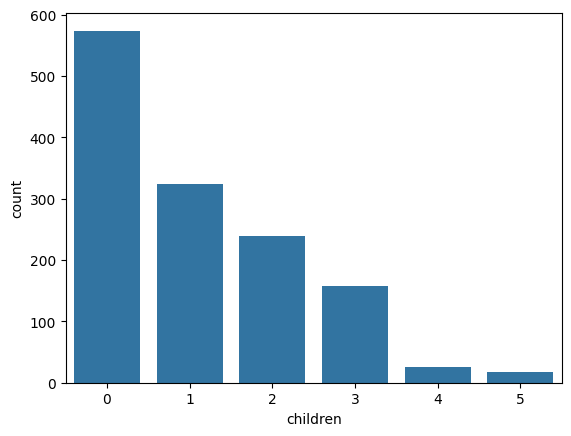

In [ ]:
sns.countplot(x=df["children"])

<Axes: xlabel='sex', ylabel='count'>

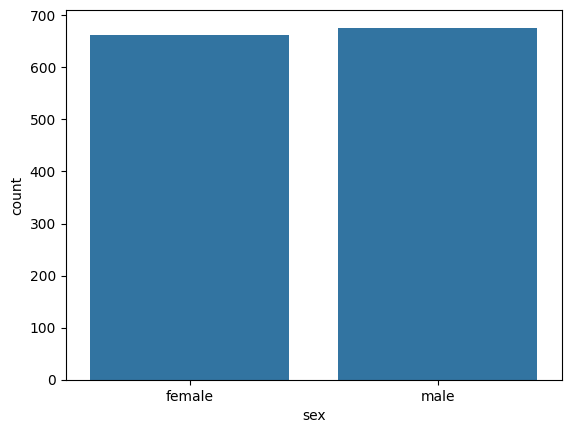

In [ ]:
sns.countplot(x=df["sex"])

<Axes: xlabel='smoker', ylabel='count'>

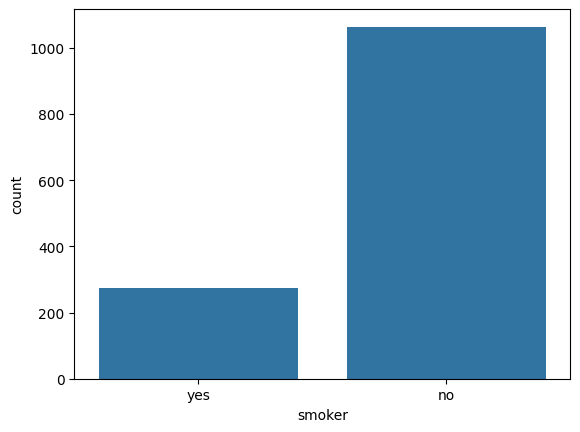

In [ ]:
sns.countplot(x=df['smoker'])

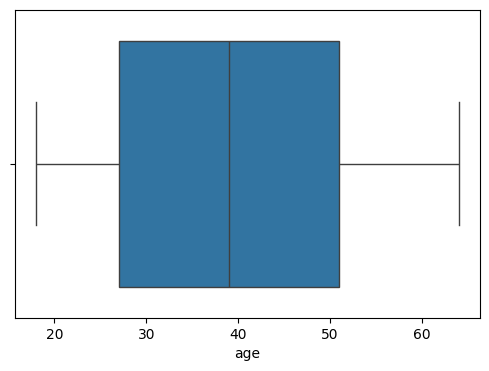

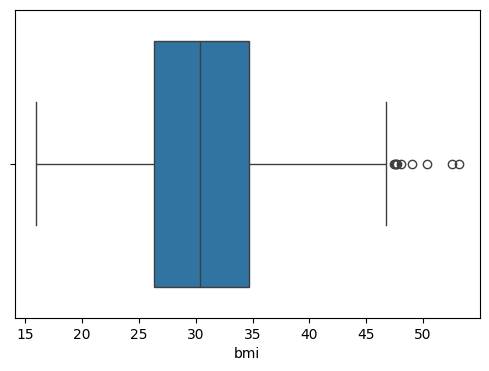

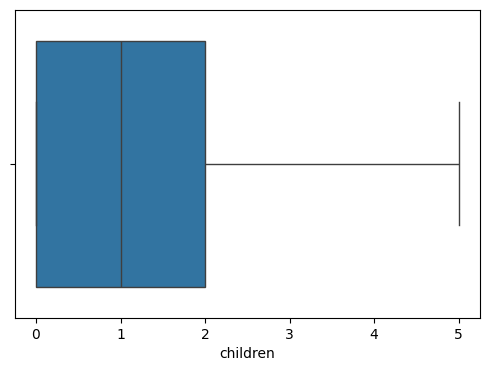

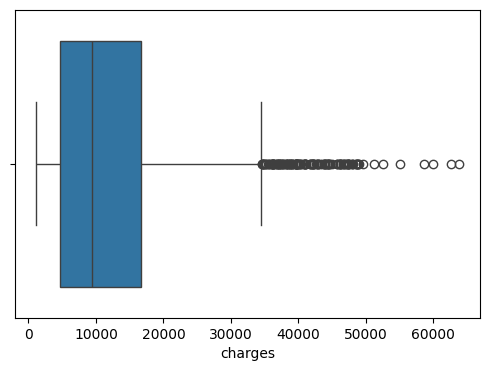

In [ ]:
for col in numeric_columns:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=df[col])

<Axes: >

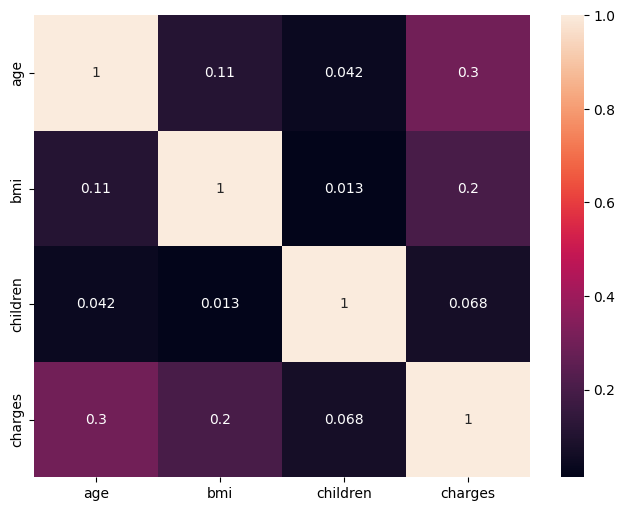

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

**Data Cleaning and Processing**

In [ ]:
df_clean = df.copy()

In [ ]:
df_clean.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df_clean.shape

(1338, 7)

In [ ]:
df_clean.drop_duplicates(inplace=True)

In [ ]:
df_clean.shape

(1337, 7)

In [ ]:
df_clean.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df_clean.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [ ]:
df_clean["sex"].value_counts()

,count
sex,
male,675
female,662


In [ ]:
df_clean["sex"] = df_clean["sex"].map({"male" : 0, "female" : 1})

In [ ]:
df_clean["smoker"] = df_clean["smoker"].map({"no" : 0, "yes" : 1})

In [ ]:
df_clean.rename(columns={
    "sex" : "is_female",
    "smoker" : "is_smoker"
}, inplace=True)

In [ ]:
df_clean

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


In [ ]:
df_clean['region'].value_counts()

,count
region,
southeast,364
southwest,325
northwest,324
northeast,324


In [ ]:
df_clean = pd.get_dummies(df_clean, columns=['region'])

In [ ]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False
3,33,0,22.705,0,0,21984.47061,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,False,True,False,False
1334,18,1,31.920,0,0,2205.98080,True,False,False,False
1335,18,1,36.850,0,0,1629.83350,False,False,True,False
1336,21,1,25.800,0,0,2007.94500,False,False,False,True


In [ ]:
df_clean = df_clean.astype(int)

In [ ]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0
1334,18,1,31,0,0,2205,1,0,0,0
1335,18,1,36,0,0,1629,0,0,1,0
1336,21,1,25,0,0,2007,0,0,0,1


**Feature Engineering and Extraction**

<Axes: xlabel='bmi', ylabel='Count'>

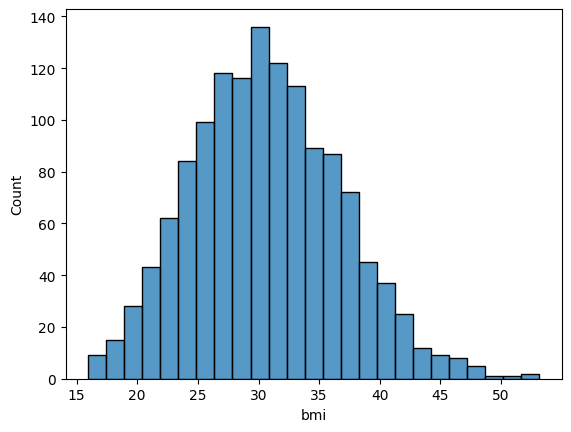

In [ ]:
sns.histplot(df['bmi'])

In [ ]:
df_clean['bmi_category'] = pd.cut(
    df_clean['bmi'],
    bins=[0,18.5,24.9,29.9,float("inf")],
    labels=["Underweight","Normal","Overweight","Obese"]
)

In [ ]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,0,1,Overweight
1,18,0,33,1,0,1725,0,0,1,0,Obese
2,28,0,33,3,0,4449,0,0,1,0,Obese
3,33,0,22,0,0,21984,0,1,0,0,Normal
4,32,0,28,0,0,3866,0,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,Obese
1334,18,1,31,0,0,2205,1,0,0,0,Obese
1335,18,1,36,0,0,1629,0,0,1,0,Obese
1336,21,1,25,0,0,2007,0,0,0,1,Overweight


In [ ]:
df_clean = pd.get_dummies(df_clean, columns=['bmi_category'])

In [ ]:
df_clean = df_clean.astype(int)

In [ ]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,0,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,0,0,0,1
1334,18,1,31,0,0,2205,1,0,0,0,0,0,0,1
1335,18,1,36,0,0,1629,0,0,1,0,0,0,0,1
1336,21,1,25,0,0,2007,0,0,0,1,0,0,1,0


In [ ]:
df_clean.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='object')

In [ ]:
from sklearn.preprocessing import StandardScaler
cols = ['age','bmi','children']
scaler = StandardScaler()
df_clean[cols] = scaler.fit_transform(df_clean[cols])

In [ ]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1,0,0,0,0,0,1
1334,-1.511647,1,0.135659,-0.909234,0,2205,1,0,0,0,0,0,0,1
1335,-1.511647,1,0.952670,-0.909234,0,1629,0,0,1,0,0,0,0,1
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0,0,1,0,0,1,0


**Pearson Correlation**

In [ ]:
round(df_clean['age'].corr(df_clean['charges']), 2)

np.float64(0.3)

In [ ]:
corr_matrix = df_clean.corr(numeric_only=True, method='pearson')
corr_matrix

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
age,1.000000,0.019814,0.108491,0.041536,-0.025587,0.298309,0.001868,0.001495,-0.012311,0.009415,-0.077174,-0.072444,-0.013608,0.086781
is_female,0.019814,1.000000,-0.046541,-0.017848,-0.076596,-0.058046,0.002008,0.012482,-0.017578,0.003767,0.023849,0.022450,0.026002,-0.046651
bmi,0.108491,-0.046541,1.000000,0.011081,0.001659,0.196236,-0.138905,-0.138620,0.271328,-0.004325,-0.286342,-0.581889,-0.322700,0.802051
children,0.041536,-0.017848,0.011081,1.000000,0.007331,0.067390,-0.023202,0.026044,-0.023492,0.021538,-0.006066,0.013103,-0.020481,0.010455
is_smoker,-0.025587,-0.076596,0.001659,0.007331,1.000000,0.787234,0.002597,-0.036321,0.068282,-0.037168,0.001138,0.023491,-0.020876,0.001169
charges,0.298309,-0.058046,0.196236,0.067390,0.787234,1.000000,0.005946,-0.038695,0.073577,-0.043637,-0.050599,-0.104042,-0.120601,0.200348
region_northeast,0.001868,0.002008,-0.138905,-0.023202,0.002597,0.005946,1.000000,-0.319842,-0.345909,-0.320493,0.068152,0.086674,0.017176,-0.098209
region_northwest,0.001495,0.012482,-0.138620,0.026044,-0.036321,-0.038695,-0.319842,1.000000,-0.345909,-0.320493,0.028712,0.039682,0.051843,-0.084223
region_southeast,-0.012311,-0.017578,0.271328,-0.023492,0.068282,0.073577,-0.345909,-0.345909,1.000000,-0.346614,-0.082693,-0.086709,-0.093030,0.170958
region_southwest,0.009415,0.003767,-0.004325,0.021538,-0.037168,-0.043637,-0.320493,-0.320493,-0.346614,1.000000,-0.010952,-0.036245,0.027591,0.004836


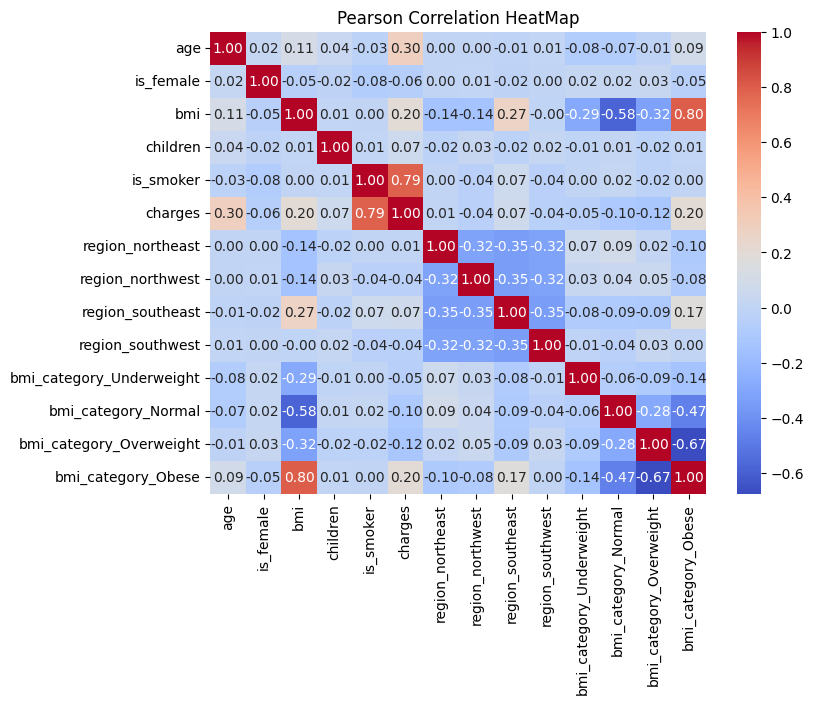

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='coolwarm')
plt.title("Pearson Correlation HeatMap")
plt.show()


In [ ]:
target_matrix = df_clean.corr(numeric_only=True, method='pearson')['charges'].drop('charges')
target_matrix

,charges
age,0.298309
is_female,-0.058046
bmi,0.196236
children,0.067390
is_smoker,0.787234
region_northeast,0.005946
region_northwest,-0.038695
region_southeast,0.073577
region_southwest,-0.043637
bmi_category_Underweight,-0.050599


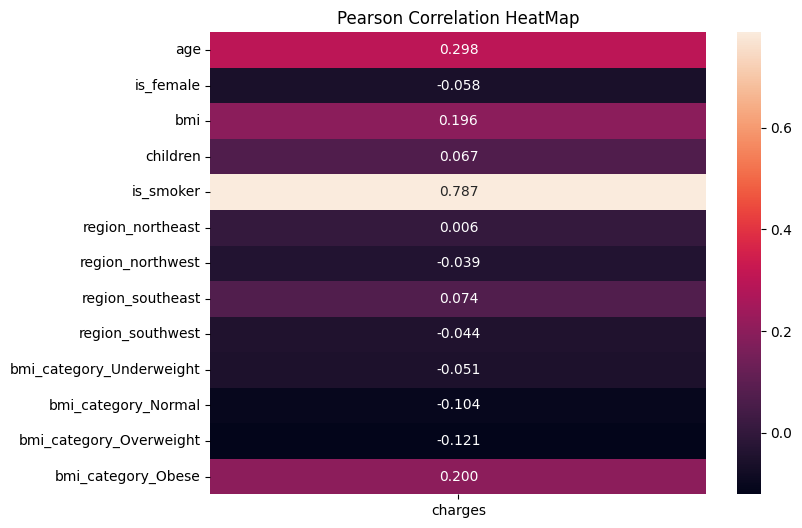

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(target_matrix.to_frame(),annot=True,fmt='.3f')
plt.title("Pearson Correlation HeatMap")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
df_clean.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='object')

In [ ]:
X = df_clean[['age', 'bmi', 'is_smoker',
       'bmi_category_Obese']]
y = df_clean['charges']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model = LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)
y_pred

array([ 8483.125541  ,  3699.7987156 , 13482.86209744, 31362.03989166,
        8615.90864518, 13063.0680537 , 29515.61046299,  1854.19974165,
       11385.55278819,  8984.88530214, 11420.02293772, 32737.02743509,
       31530.12360011, 16668.97846528,  9622.74998637,  7978.04396094,
        5428.96182261, 32704.21819501,  2777.41445599,  4034.30522303,
        5428.96182261, 28793.28869717, 13481.20118798, 29548.41970307,
       31949.08718912,  5680.67215791, 34632.61334109, 38494.38636161,
       12477.6816657 , 12644.10446468,  8030.52225718, 13314.77838899,
         763.7317736 , 11418.36202827, 38238.52375267, 13315.60884372,
        1433.57524318,  3449.74928976, 32403.35138239,  8229.75429624,
        6434.14225435, 29886.2480294 , 34466.1905421 , 13148.35559001,
        7477.11465453,  3448.0883803 ,  5510.92754001,  7558.2499172 ,
        3448.0883803 , 10127.83156643,  7442.644505  , 10964.097835  ,
       30304.38116369,  5428.96182261, 11133.84245289, 11219.1299892 ,
      

In [ ]:
from sklearn.metrics import r2_score

"""R-Square"""
r2 = r2_score(y_test,y_pred)
print(r2)

"""Adjusted R-Square"""
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))
print(adjusted_r2)

0.8038308361613097
0.8008472747341053


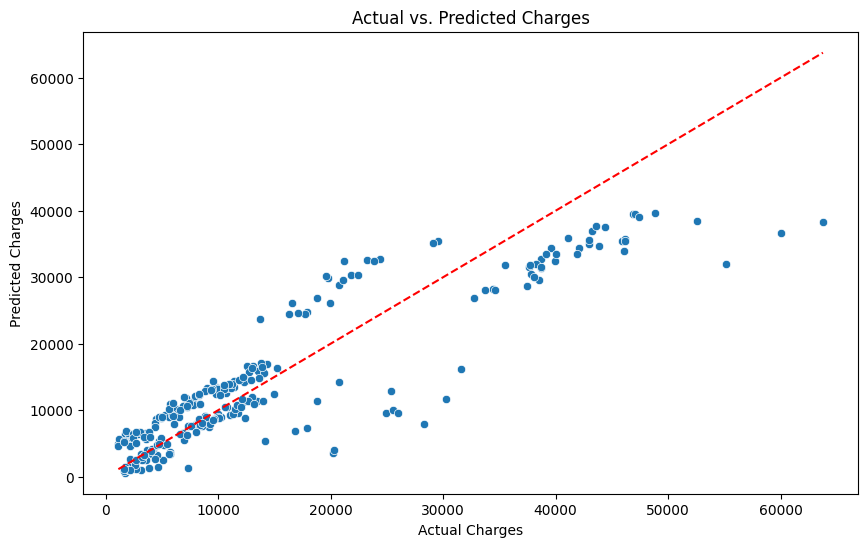

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs. Predicted Charges')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') # Add a diagonal line for perfect prediction
plt.show()

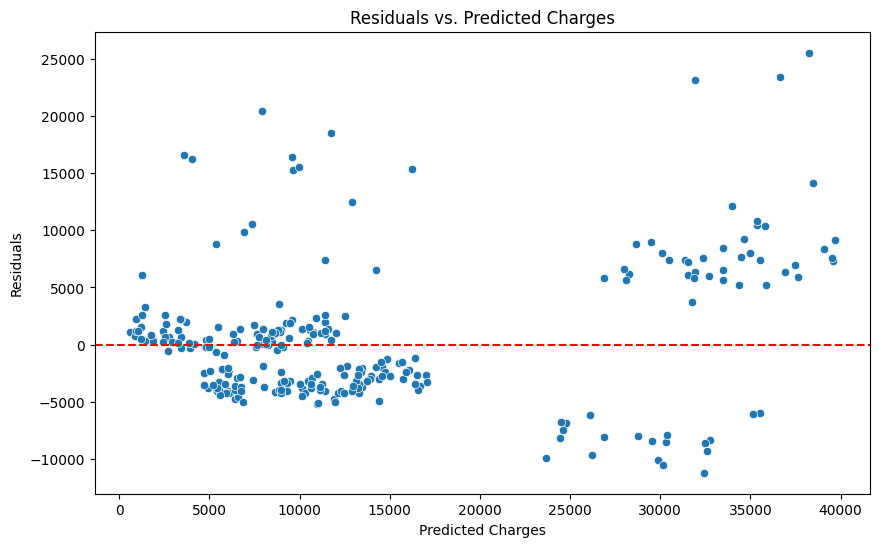

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Charges')
plt.ylabel('Residuals')
plt.title('Residuals vs. Predicted Charges')
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error (MAE): {mae}")

Mean Absolute Error (MAE): 4277.328192268136


In [ ]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse}")

Mean Squared Error (MSE): 36047277.56593764
